# DDRL SARSA {#sec-ddrlsarsa}

In this section, we provide functions that are specific to the SARSA version of Distributional Deterministic Reinforcement Learning.

First, we import everything necessary:

In [ ]:
 #| default_exp Agents.DDRLSarsa

In [ ]:
 #| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
 #| export
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

import itertools as it

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from pyDDRL.Agents.DDRLBase import DDRLBase

from pyDDRL.Agents.Methods import quantile, expectile, weights

In [ ]:
# imports for this notebook
import matplotlib.pyplot as plt
from pyCRLD.Utils import FlowPlot as fp

# test environment
from pyDDRL.Environments.RiskRewardDilemma import RiskRewardDilemma

## Test environment

We use a risk-reward dilemma (defined in @sec-rrdilemma ) as a test environment. In this task, the agent can choose between a high-risk, high-gain option, and a low-risk, low-gain option. More precisely, we give our environment the following structure:

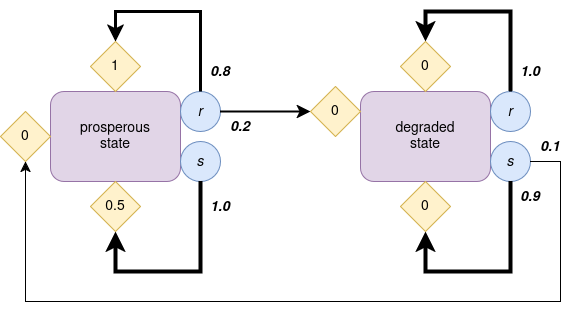

If an agent chooses the risky action $r$ in the prosperous state, it gets a higher reward. But there is a probability that it transitions to a degraded state, where it gets no reward. The only way to escape this degraded state is to choose the safe action, $s$.

In [ ]:
# Define environment
env = RiskRewardDilemma(pc=0.2, pr=0.1, rc=0.5, rr=1, rd=0)
env

RiskRewardDilemma_0.2_0.1_0.5_1_0

## DDRL SARSA class

Now, we can define the DDRL SARSA class:

In [ ]:
 #| export
class DDRLSarsa(DDRLBase):
    """
    Base class for SARSA version of DDRL in strategy space.        
    """
    
    def __init__(self,
                 env,
                 **kwargs):
    
        super().__init__(env, **kwargs)

We consider the following agent-environment interface:
* 1 agent with learning rate $\alpha=0.1$, discount factor $\gamma=0.4$, choice intensity $\beta=50$;
* playing the aforementioned risk-reward dilemma.

In [ ]:
aei = DDRLSarsa(env,
                nr_reward_bins=29,
                discretization_sigma=0.1,
                learning_rates=0.1,
                choice_intensities=50.,
                discount_factors=0.4,
                Rmin=-0.5,
                Rmax=1.5,
                use_prefactor=True)

## Computing distributions in DDRL-SARSA

Now we can compute and plot all the distributions we need.

### Q-return distributions $Q^{i,s,a,v}$ and ${}^{next}Q^{i,s,a,\acute v}$

In detRL, the next-state Q-value for agent $i$ taking action $a$ in state $s$ is averaged over other agents' actions $\boldsymbol{a}^{j}$ and next states $\acute s$:
$${}^{next}Q^{i,s,a} = \sum_{\acute s} \sum_{\boldsymbol{a}^{j}} X^{j,s,\boldsymbol{a^{j}}} T^{s,a,\boldsymbol{a}^{j},\acute s} V^{i, \acute s}$$

In a distributional framework, therefore,
$${}^{next}Q^{i,s,a,\acute v} = \sum_{\acute s} \sum_{\boldsymbol{a}^{j}} X^{j,s,\boldsymbol{a^{j}}} T^{s,a,\boldsymbol{a}^{j},\acute s} V^{i, \acute s,\acute v}$$

Just like state values, Q-values conform to the Bellman equation. Therefore, we can obtain the Q-return distribution for agent $i$, action $a$ and state $s$, from the next-state Q-return distribution for $(i,a,s)$, the reward distribution for $(i,a,s)$, and the smoothed Bellman Kronecker delta:
$$Q^{i,s,a,v} =  \sum_{r, \acute v} \delta^{i,v,r,\acute v} R^{i,s,a,r} \cdot {}^{next}Q^{i,s,a,\acute v}$$

In [ ]:
 #| export
@partial(jit, static_argnums=0)        
def Qisaq(self:DDRLSarsa,
          Xisa:jnp.ndarray, # Joint strategy
          Tisas:jnp.ndarray=None, # Optional transition for speed-up
          ) -> jnp.ndarray:  # Average state-action values
    """
    Compute Q-return distribution Qisaq, given joint strategy `Xisa`.
    """
    Risar = self.Risar(Xisa)
    b_ivrv_ = self.b_ivrv_
    Visv = self.Visv(Xisa) 
    Tisas = self.Tisas(Xisa) if Tisas is None else Tisas 

    i = 0; s = 1; a = 2; s_ = 3; v = 4; v_ = 5; r = 6
    nextQisaq = jnp.einsum(Tisas, [i,s,a,s_], Visv, [i,s_,v], [i,s,a,v],
                           optimize=self.opti)

    Qisaq = jnp.einsum(b_ivrv_, [i,v,r,v_], Risar, [i,s,a,r], nextQisaq, [i,s,a,v_], [i,s,a,v])
    
    return Qisaq

DDRLSarsa.Qisaq = Qisaq

We assume that, in both states, the agent takes the safe action with probability 0.2, and the risky action with probability 0.8.

In [ ]:
# agent's strategy
X = np.ones((1, 2, 2)) * 0.2
X[:,:,1] = 1 - X[:,:,0]
X

array([[[0.2, 0.8],
        [0.2, 0.8]]])

Now we can plot the Q-return distribution for each action in the prosperous state.

In [ ]:
Qq = aei.Qisaq(X)

# Plot Q-return distribution Qisaq for both actions
fig, axes = plt.subplots(1, 2, figsize=(8,3))
actions = ["safe", "risky"]
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(aei.gridpoints, Qq[0,0,a,:], width=0.9*aei.gridwidth, color='k')
    rm = np.dot(aei.gridpoints, Qq[0,0,a,:])
    ax.plot([rm, rm], [0.0, 0.02], c='red', lw=5)
    ax.set_xlabel("v")
    ax.set_ylabel(r"$Q^{i,s,a,v}$")
    ax.set_title("Q-return distribution for "+str(actions[a])+" action")
    ax.set_ylim([0, np.max(Qq[0,0,:,:]+0.01)])
plt.show()

<Figure size 2400x900 with 2 Axes>

Now we can compute and plot the next-state Q-return distribution:

In [ ]:
 #| export
@partial(jit, static_argnums=0)
def NextQisaq(self:DDRLSarsa,
              Xisa           # Joint strategy
              ) -> jnp.ndarray: # Next values       
    """
    Compute next-state Q-return distribution NextQisaq,
    given joint strategy `Xisa`.
    """
    Qisaq = self.Qisaq(Xisa)
    
    i = 0; a = 1; s = 2; s_ = 3; q = 4
    j2k = list(range(6, 6+self.N-1))  # other agents
    b2d = list(range(6+self.N-1, 6+self.N-1 + self.N))  # all actions
    e2f = list(range(5+2*self.N, 5+2*self.N + self.N-1))  # all other acts

    sumsis = [[j2k[l], s, e2f[l]] for l in range(self.N-1)]  # sum inds
    otherX = list(it.chain(*zip((self.N-1)*[Xisa], sumsis)))

    NextQisq = jnp.einsum(Qisaq, [i, s_, a, q], Xisa, [i, s_, a], [i, s_, q])
                    
    args = [self.Omega, [i]+j2k+[a]+b2d+e2f] + otherX +\
    [self.T, [s]+b2d+[s_], NextQisq, [i, s_, q], [i, s, a, q]]                                            
    return jnp.einsum(*args, optimize=self.opti)

DDRLSarsa.NextQisaq = NextQisaq 

In [ ]:
Qq = aei.NextQisaq(X)

# Plot next-state Q-return distribution nextQisaq for both actions
fig, axes = plt.subplots(1, 2, figsize=(8,3))
actions = ["safe", "risky"]
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(aei.gridpoints, Qq[0,0,a,:], width=0.9*aei.gridwidth, color='k')
    rm = np.dot(aei.gridpoints, Qq[0,0,a,:])
    ax.plot([rm, rm], [0.0, 0.02], c='red', lw=5)
    ax.set_xlabel("v")
    ax.set_ylabel(r"${}^{next} Q^{i,s,a,v}$")
    ax.set_title("next-state Q-return distribution for "+str(actions[a])+" action", 
                 fontsize=10)
    ax.set_ylim([0, np.max(Qq[0,0,:,:]+0.01)])
plt.show()

<Figure size 2400x900 with 2 Axes>

## (Biased) Q-value $Q^{i,s,a}$

A classic estimate of the Q-value is the mean of the Q-return distribution. But a biased agent will get an optimistic or a pessimistic estimate of this distribution. To obtain this biased estimate, we can apply the quantile, expectile, or weights method to the return distribution. To know more about these methods, please refer to @sec-biasing-methods . 

Here, we compute the (biased) Q-value from the previous Q-return distribution. When the weights method is used, we take the Q-value $Q^{i,s}$ as a baseline:

In [ ]:
 #| export
@partial(jit, static_argnums=0)        
def Qisa(self,
          Xisa:jnp.ndarray, # Joint strategy
          ) -> jnp.ndarray:  # Average state-action values
    """
    Compute Q-value for state `s` and action `a`.
    """
    Qisaq = self.Qisaq(Xisa)  # Q-return distrib
    gpoints = jnp.ones((self.nr)) * -1
    gpoints = gpoints.at[:].set(self.gridpoints)
    Qisa = jnp.einsum('ijkl,l->ijk', Qisaq, gpoints)
    i = 0; a = 1; s = 2
    Qis = jnp.einsum(Qisa, [i, s, a], Xisa, [i, s, a], [i, s])  # baseline
    # Baseline: mean of Qisaq
    Qis_expanded = jnp.expand_dims(Qis, axis=2)  # shape (N, Z, 1)
    baseline = jnp.repeat(Qis_expanded, self.M, axis=2)  # shape (N, Z, M)
    if self.method=='mean':  # take mean
        return Qisa
    elif self.method=='quantile':  # use quantile
        return quantile(self.tau, Qisaq, gpoints)
    elif self.method=='expectile':  # use expectile
        return expectile(self.tau, Qisaq, gpoints)
    elif self.method=='weights':  # use weights
        w = jnp.ones((self.N, self.Z, self.M, len(self.gridpoints)))
        n = jnp.newaxis
        upper = self.gridpoints[n,n,n,:] >= baseline[:,:,:,n]
        upper = upper * (self.wU - 1)
        w = w + upper
        wQisaq = weights(w, Qisaq, gpoints)
        Qisa = jnp.einsum('ijkl,l->ijk', wQisaq, gpoints)  # take the new distrib's mean
        return Qisa

DDRLSarsa.Qisa = Qisa 

Here, we define an optimistic agent, and we compare neutral and optimistic estimates of the Q-value.

In [ ]:
## Define optimistic agent

aei_opt = DDRLSarsa(env,
                    nr_reward_bins=29,
                    discretization_sigma=0.1,
                    learning_rates=0.1,
                    choice_intensities=50.,
                    discount_factors=0.4,
                    Rmin=-0.5,
                    Rmax=1.5,
                    use_prefactor=True,
                    method="weights",
                    wU=3)

In [ ]:
Qq = aei.Qisaq(X)
qm = aei.Qisa(X)[0,0]
qm_opt = aei_opt.Qisa(X)[0,0]

# Plot Q-value distribution Qisaq for both arms
fig, axes = plt.subplots(1, 2, figsize=(8,3))
actions = ["safe", "risky"]
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(aei.gridpoints, Qq[0,0,a,:], width=0.9*aei.gridwidth, color='k')
    ax.plot([qm[a], qm[a]], [0.0, 0.02], c='red', lw=5, 
            label="neutral Q-value")
    ax.plot([qm_opt[a], qm_opt[a]], [0.0, 0.02], c='limegreen', 
            lw=5, label="optimistic Q-value")
    ax.set_xlabel("v")
    ax.set_ylabel(r"$Q^{i,s,a,v}$")
    ax.set_title("Q-return distribution for "+str(actions[a])+" action")
    ax.set_ylim([0, np.max(Qq[0,0,:,:]+0.01)])    
axes[1].legend(bbox_to_anchor=(0.9, 0.6))

plt.show()

<Figure size 2400x900 with 2 Axes>

## Temporal-difference error

From the Q-value estimate, we can compute the temporal-difference error:

In [ ]:
 #|export
@partial(jit, static_argnums=(0,2))
def TDerror(self:DDRLSarsa,
            Xisa,  # Behavior profiles
            norm=False) -> jnp.ndarray:
    """
    Compute reward-prediction/temporal-difference error for 
    strategy SARSA dynamics, given joint strategy `Xisa`.
    """
    Q = self.Qisa(Xisa)
    n = jnp.newaxis
    E = Q - (1 / self.beta[:,n,n]) * jnp.log(Xisa)
    E *= self.beta[:,n,n]
    
    E = E - E.mean(axis=2, keepdims=True) if norm else E
    return E

DDRLSarsa.TDerror = TDerror

It is now possible to plot our SARSA agent's deterministic trajectory in phase space.

In [ ]:
# Flow Plot

fig, ax = plt.subplots(1,1, figsize=(3,3))
x = ([0], [0], [0])  # prosperous state
y = ([0], [1], [0])  # degraded state

# Flow plot
fp.plot_strategy_flow(aei, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax)

# Example trajectory
Xinit = np.ones((1,2,2)) * 0.8
Xinit[0,1,0] = 0.2
Xinit[:,:,1] = 1 - Xinit[:,:,0]
trj, fpr = aei.trajectory(Xinit, Tmax=1000, tolerance=1e-6)
fp.plot_trajectories([trj], x, y, fprs=[fpr], axes=ax, cols=['red'])
    
ax.set_xlabel("prob. to act safe in prosp. state", fontsize=9)
ax.set_ylabel("prob. to act safe in deg. state", fontsize=9)

plt.show()

<Figure size 900x900 with 1 Axes>

In [ ]:
 #| hide
import nbdev; nbdev.nbdev_export()